In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scienceplots

In [22]:
plt.style.use(['science', 'no-latex'])

In [23]:
df = pd.read_csv("hamiltonian_comparison.csv", index_col=None)
print(df.head())

  hamiltonian  cutoff   k  nqubits  nterms_kept  nterms_dropped  dropped_l1  \
0          ts  0.0100  44       44         3622          578808  317.523335   
1          ts  0.0010  44       44        96558          485872   85.153535   
2          ts  0.0001  44       44       285858          296572    5.141923   
3     product  0.0100  44       44         3470          576072  247.868851   
4     product  0.0010  44       44        72282          507260   70.661589   

   ngroups         shots  ngroups_reincorporated  shots_reincorporated  \
0       53  6.909754e+06                  578861          4.043306e+10   
1      762  8.622248e+07                  486634          3.907059e+09   
2     1368  1.156411e+08                  297940          1.950869e+08   
3       48  6.010873e+06                  576120          2.476491e+10   
4      643  6.642478e+07                  507903          2.736705e+09   

   max_mpo_bond  ngroups_truncated  epsilon  dmrg_energy  
0            64      

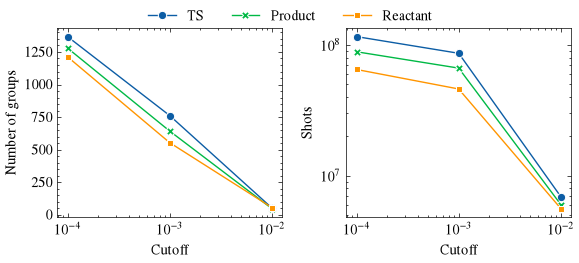

In [24]:
labels = {"ts": "TS", "reactant": "Reactant", "product": "Product"}
plot_df = df.assign(Hamiltonian=df["hamiltonian"].map(labels))
line_kw = dict(data=plot_df, x="cutoff", hue="Hamiltonian", style="Hamiltonian",
               markers=True, dashes=False, legend=False)

fig, ax = plt.subplots(1, 2, figsize=(6, 2.6))
sns.lineplot(ax=ax[0], y="ngroups", **line_kw)
ax[0].set_xscale("log")
ax[0].set_xlabel("Cutoff")
ax[0].set_ylabel("Number of groups")
sns.lineplot(ax=ax[1], y="shots", legend=True, **{k: v for k, v in line_kw.items() if k != "legend"})
ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].set_xlabel("Cutoff")
ax[1].set_ylabel("Shots")

# One shared legend above both panels instead of seaborn's per-axis legend.
handles, legend_labels = ax[1].get_legend_handles_labels()
ax[1].get_legend().remove()
fig.legend(handles, legend_labels, loc="upper center", ncol=len(legend_labels),
           frameon=False, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
fig.savefig("hamiltonian_comparison.pdf", bbox_inches="tight")